Thư viện

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from channel import QPSK, AWGN, rician_channel, equalize, compute_ber, ber_qpsk_rician

Thông Số

In [2]:
f_c = 12            # GHz
d = 36000           # km
BW = 1e6            # Hz, giả sử tốc độ symbol = BW nên SNR = Es/N0
G_tx = 30           # dBi
G_rx = 30           # dBi
T_sys = 250         # K
k_boltz = 1.38e-23
num_bits = 1_000_000
K_factor_dB = 10
P_tx_dBW_range = np.arange(0, 15, 1)

Tính thông số

In [3]:
FSPL_dB = 92.44 + 20 * np.log10(f_c) + 20 * np.log10(d)    # f_c (GHz), d (km)
K_factor = 10 ** (K_factor_dB / 10)
N_noise_dBW = 10 * np.log10(k_boltz * T_sys * BW)
SNR_dB_range = P_tx_dBW_range + G_tx + G_rx - FSPL_dB - N_noise_dBW
print(f"FSPL (dB): {FSPL_dB:.2f}")
print(f"Noise Power (dBW): {N_noise_dBW:.2f}")

FSPL (dB): 205.15
Noise Power (dBW): -144.62


BER Lý thuyết

In [4]:
theory_ber = ber_qpsk_rician(SNR_dB_range, K_factor)
for snr, ber in zip(SNR_dB_range, theory_ber):
    print(f"   SNR: {snr:6.2f} dB | BER Theory: {ber:.6e}")

   SNR:  -0.53 dB | BER Theory: 1.834052e-01
   SNR:   0.47 dB | BER Theory: 1.568047e-01
   SNR:   1.47 dB | BER Theory: 1.305446e-01
   SNR:   2.47 dB | BER Theory: 1.053719e-01
   SNR:   3.47 dB | BER Theory: 8.207351e-02
   SNR:   4.47 dB | BER Theory: 6.138291e-02
   SNR:   5.47 dB | BER Theory: 4.386780e-02
   SNR:   6.47 dB | BER Theory: 2.982687e-02
   SNR:   7.47 dB | BER Theory: 1.923169e-02
   SNR:   8.47 dB | BER Theory: 1.174187e-02
   SNR:   9.47 dB | BER Theory: 6.795518e-03
   SNR:  10.47 dB | BER Theory: 3.743592e-03
   SNR:  11.47 dB | BER Theory: 1.978077e-03
   SNR:  12.47 dB | BER Theory: 1.013484e-03
   SNR:  13.47 dB | BER Theory: 5.103192e-04


Mô Phỏng

In [5]:
def run_simulation(snr_db_list):
    qpsk = QPSK()
    sim_ber = []
    for P_tx, snr_db in zip(P_tx_dBW_range, snr_db_list):
        bits = np.random.randint(0, 2, num_bits)
        symbols_tx = qpsk.modulate(bits)

        # fading nhanh: mỗi symbol một h, nên 1 lần chạy đã lấy trung bình trên nhiều kênh
        h = rician_channel(len(symbols_tx), K_factor)
        y, N0 = AWGN(h * symbols_tx, snr_db)
        bits_rx = qpsk.demodulate(equalize(y, h, N0, 'zf'))

        ber = compute_ber(bits, bits_rx)
        sim_ber.append(ber)
        print(f"   P_tx: {P_tx:2d} dBW | SNR: {snr_db:6.2f} dB | BER Sim: {ber:.6e}")
    return np.array(sim_ber)

Chạy mô phỏng

In [6]:
sim_ber = run_simulation(SNR_dB_range)

   P_tx:  0 dBW | SNR:  -0.53 dB | BER Sim: 1.826360e-01
   P_tx:  1 dBW | SNR:   0.47 dB | BER Sim: 1.567110e-01
   P_tx:  2 dBW | SNR:   1.47 dB | BER Sim: 1.302870e-01
   P_tx:  3 dBW | SNR:   2.47 dB | BER Sim: 1.049390e-01
   P_tx:  4 dBW | SNR:   3.47 dB | BER Sim: 8.199700e-02
   P_tx:  5 dBW | SNR:   4.47 dB | BER Sim: 6.139800e-02
   P_tx:  6 dBW | SNR:   5.47 dB | BER Sim: 4.374700e-02
   P_tx:  7 dBW | SNR:   6.47 dB | BER Sim: 2.974700e-02
   P_tx:  8 dBW | SNR:   7.47 dB | BER Sim: 1.938800e-02
   P_tx:  9 dBW | SNR:   8.47 dB | BER Sim: 1.177200e-02
   P_tx: 10 dBW | SNR:   9.47 dB | BER Sim: 6.748000e-03
   P_tx: 11 dBW | SNR:  10.47 dB | BER Sim: 3.774000e-03
   P_tx: 12 dBW | SNR:  11.47 dB | BER Sim: 2.047000e-03
   P_tx: 13 dBW | SNR:  12.47 dB | BER Sim: 1.033000e-03
   P_tx: 14 dBW | SNR:  13.47 dB | BER Sim: 5.600000e-04


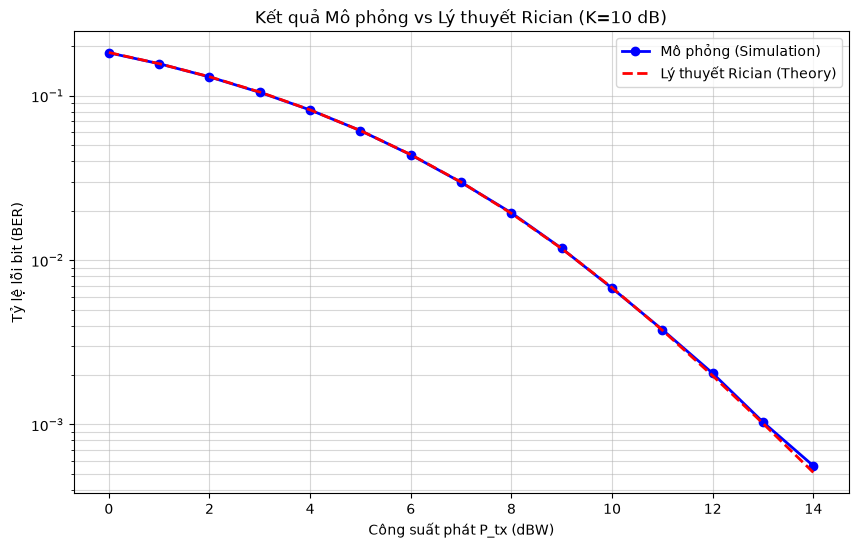

In [7]:
plt.figure(figsize=(10, 6))
plt.semilogy(P_tx_dBW_range, np.where(sim_ber > 0, sim_ber, np.nan), 'bo-', markersize=6, linewidth=2, label='Mô phỏng (Simulation)')
plt.semilogy(P_tx_dBW_range, theory_ber, 'r--', linewidth=2, label='Lý thuyết Rician (Theory)')
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.xlabel('Công suất phát P_tx (dBW)')
plt.ylabel('Tỷ lệ lỗi bit (BER)')
plt.title(f'Kết quả Mô phỏng vs Lý thuyết Rician (K={K_factor_dB} dB)')
plt.legend()
plt.show()